Follow the notebook to build basis change operator to change basis from y lattice to y subbands

In [236]:
from config import *

import time 

import Operators2D as Op

class twoD_Minimal_Model:

    def __init__(self, n, nsm, nsc, m, ax, ay, omega=1, alphat=0, delta=0, meff_sc=1, meff_sm = 1 , mu_sc = 0, mu_sm=0, dis_mean=0, dis_var=1, px=False, py=False,  epsilon=0):

        """
        Initializes a new instance of the oneD_Minimal_Model class.
        
        Args:
            n (int): The number of horizontal lattice points of the system.
            nsm (int): The number of horizontal lattice points of the semiconductor weak link.
            nsc (int): The number of horizontal lattice points of the superconductor on both sides.
            m (int): The number of vertical lattive points
            ax (float): The horizontal (x) lattice spacing.
            ay (float): The vertical (y) lattice spacing.
            meff (float): Effective mass 
            alphat (float): spin orbit coupling constant
            mu_s (float): chemical potential of the superconducting region of SNS
            mu_sm (float): chemical potential of the semiconductingconducting region of SNS
            px (bool, optional): Flag indicating periodicity in x direction. Defaults to False.
            epsilon (float): Kx^4 prefactor to remove higher k states from dipping

        Notes:
            - The ordering of lattice points for kx, kxsq, kxcu(imported for operator class file) is from left to right, bottom to top, similar to x and y axis in 2D g

        """

        self.n = n
        self.nsm = nsm
        self.nsc = nsc
        self.m = m
        self.ax = ax
        self.ay = ay
        self.omega = omega
        self.meff_sc = meff_sc
        self.meff_sm = meff_sm
        self.alphat = alphat
        self.delta = delta
        self.mu_sc = mu_sc
        self.mu_sm  = mu_sm
        self.dis_mean = dis_mean
        self.dis_var = dis_var
        self.px = px
        self.py = py
        self.epsilon = epsilon
        self.twodOP = Op.Operators_2d(self.n, self.m, self.ax, self.ay, self.px, self.py)

    def ysq_matrix(self):

        row = np.empty(0)
        col = np.empty(0)
        data = np.empty(0)

        shift = (((self.m//2))*self.ay)

        #print('SHIFT YSQ: ', shift )

        for j in range(self.m):

            for i in range(self.n):
            
                row = np.append(row, j*self.n + i)
                col = np.append(col, j*self.n + i)
                data = np.append(data, ((j)*self.ay-shift)**2)

        M = csr_matrix((data,(row,col)),shape=(self.m*self.n, self.m*self.n))

        return M

    def SHO_wvfn(self, ne, yj=0):

        """
        Return Phi__ne(yj) where yj is the jth index and ne is the quantum number of SHO wavefunction and the whole array
        """

        # define constant of SHo wavefunctions 

        #kappa = self.omega/hbm*self.meff_sm
        kappa = self.omega/hbm*self.meff_sm
        normalization_const = 1/math.sqrt(2**ne * math.factorial(ne))*(kappa/2/math.pi)**(0.25)*self.ay**(0.5)

        # Create the Hermite polynomial 
        coefficients = np.zeros(ne+1)
        coefficients[ne] = 1  # Setting the leading coefficient as per the physicist's definition
        
        H_n = Hermite(coefficients)

        shift = (((self.m//2))*self.ay) ### same shift from as the ysq_matrix 

        #print('SHIFT Y_array: ', shift )

        indices = np.arange(self.m)

        y_array = (indices ) * self.ay  - shift

        y_array_n = math.sqrt(kappa/2)*y_array

        Herm_array = H_n(y_array_n)

        #return normalization_const*np.exp(-kappa/4*y_array**2)*Herm_array, y_array

        wvfn = normalization_const*np.exp(-kappa/4*y_array**2)*Herm_array
        return wvfn[yj], wvfn       

    def SHO_pot(self):

        return 1/4/hbm*self.meff_sm*self.omega**2*self.ysq_matrix() 
    
    def SHO_Hamiltonian_in_y(self,kx=0, ky=0):

        return self.SHO_pot() + hbm/self.meff_sm* self.twodOP.KySq(ky) + hbm/self.meff_sm* self.twodOP.KxSq(kx)

    def SHO_Hamiltonian_in_y_ph(self,ky=0):

        M = bmat([
           [self.SHO_Hamiltonian_in_y(ky), None],
           [None, -self.SHO_Hamiltonian_in_y(-ky).conjugate()]
       ])
        
        return M

    '''
    def U_dag(self, my):

        """

        Returns sparse matrix of shape(my n X mn)

        Args:
            my: No. of y subbands 

        """
        row = np.empty(0)
        col = np.empty(0)
        data = np.empty(0)        

        for i in range(self.n):

            for j in range(my):

                d, p = self.SHO_wvfn(ne= j, yj=0)

                for k in range(self.m):

                    row = np.append(row, j*self.n + i)    
                    col = np.append(col, k*self.n + i)               
                    data = np.append(data, p[k] )

        M = csr_matrix((data,(row,col)),shape=(my*self.n, self.m*self.n))

        return M    
    '''
    def U_dag(self, my):

        """
        Returns sparse matrix of shape (my * n, m * n)

        Args:
            my: No. of y subbands 
        """
        row = []
        col = []
        data = []        

        for i in range(self.n):
            for j in range(my):
                d, p = self.SHO_wvfn(ne=j, yj=0)
                for k in range(self.m):
                    row.append(j * self.n + i)    
                    col.append(k * self.n + i)               
                    data.append(p[k])

        M = csr_matrix((data, (row, col)), shape=(my * self.n, self.m * self.n))

        return M
    
    def U_dag_ph(self, my=1):

        M = bmat([
            [ self.U_dag(my), None],
            [None, -self.U_dag(my).conjugate()],
        ])

        return M

    

In [237]:
N = 3
NSM = 3 
NSC = 1 
M = 13 
AX = 3
AY = 4 

A = twoD_Minimal_Model(N,NSM,NSC,M,AX,AY)

#print(A.ysq_matrix())

#ysq = A.ysq_matrix()

c, b = A.SHO_wvfn(1)
print(b.shape)
print(c)
#print(b)

#d = A.SHO_pot()

(13,)
-0.04525765609270401


comparign analytical wavefunction to the one calculated from the lattice

In [247]:
N = 1
NSM = 1 
NSC = 1            ### DOESNT' MATTER WHAT WE PTU N, NSSC, NSM AS ATLEAST FOR THIS NOTEBOOK  
M = 1000 
AX = 3
AY = 2.7 
LY = (M//10)*AY

MEFF_SC = 0.023 

#OMEGA =  2*4*hbm/LY**2/MEFF_SC

OMEGA =  2*4*hbm/LY**2/MEFF_SC

KNUM= 4 

A = twoD_Minimal_Model(N,NSM,NSC,M,AX,AY,OMEGA,meff_sc=MEFF_SC, meff_sm=MEFF_SC)

H = A.SHO_Hamiltonian_in_y()

E, V = eigsh(H , k = KNUM, sigma=0 )

print(E)

print(V.shape)

[368.51986414 368.70179523 368.88371724 369.06563014]
(1000, 4)


In [248]:
print(OMEGA/2)

0.09097009785507267


(1000,)


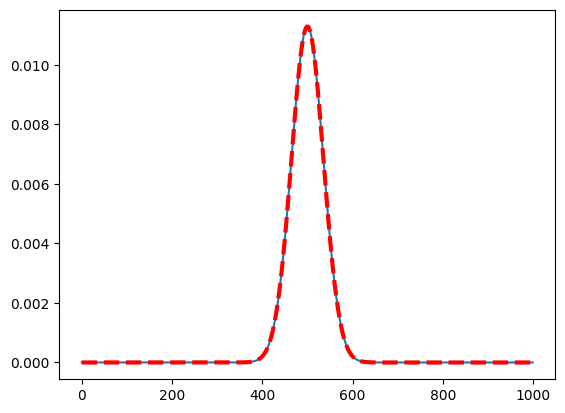

In [249]:
#b,c = A.SHO_wvfn(0)
c, b = A.SHO_wvfn(0)
print(b.shape)

#D = V[:,0].reshape(M,N)

#print(D.shape)

plt.plot(abs(V[:,0])**2)
plt.plot( abs(b)**2, linestyle='dashed',color='red', lw=3)

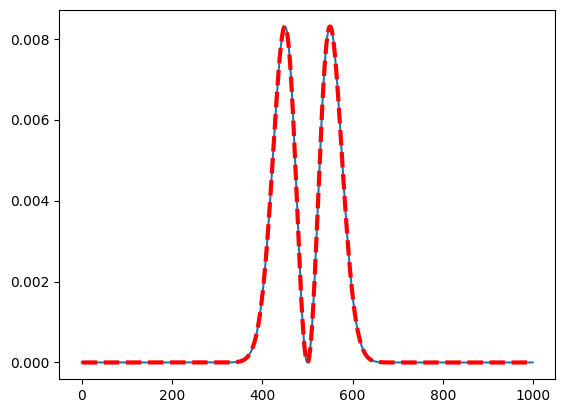

In [250]:
c, b = A.SHO_wvfn(1)

plt.plot(abs(V[:,1])**2)
plt.plot( abs(b)**2, linestyle='dashed',color='red', lw=3)

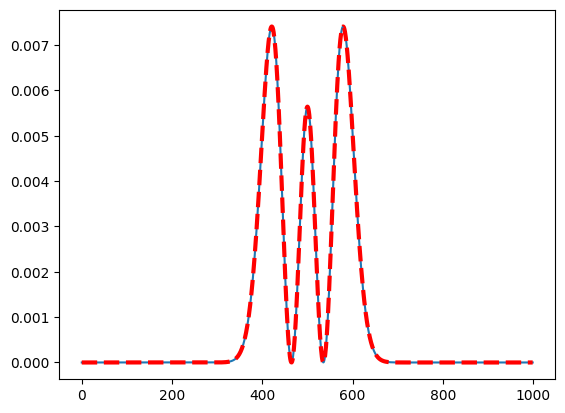

In [251]:
c, b = A.SHO_wvfn(2)

plt.plot( abs(V[:,2])**2)
plt.plot(  abs(b)**2, linestyle='dashed',color='red', lw=3)

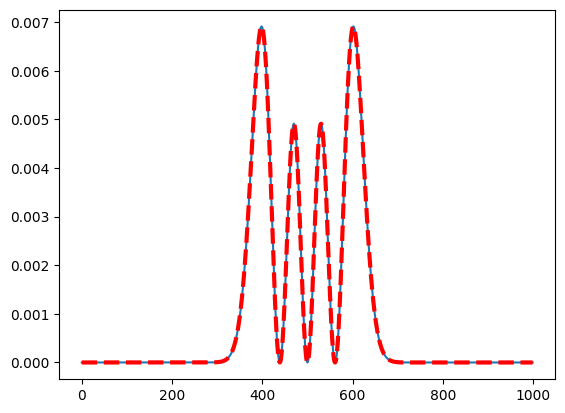

In [252]:
b,c = A.SHO_wvfn(3)

plt.plot( abs(V[:,3])**2)
plt.plot(  abs(c)**2, linestyle='dashed',color='red', lw=3)

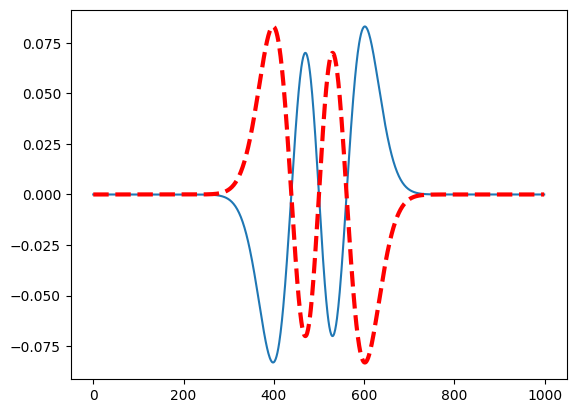

In [253]:
d, b = A.SHO_wvfn(3)

#d = A.ysq_matrix().toarray()

plt.plot( (V[:,3]))
plt.plot(  -(b), linestyle='dashed',color='red', lw=3)

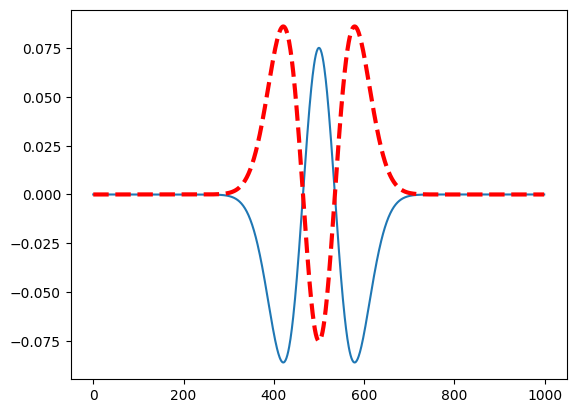

In [254]:
b,c = A.SHO_wvfn(2)

plt.plot( (V[:,2]))
plt.plot(  c, linestyle='dashed',color='red', lw=3)

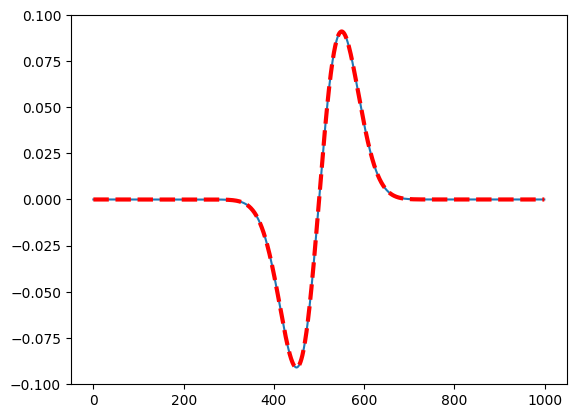

In [255]:
c,b = A.SHO_wvfn(1)

plt.plot( (V[:,1]))
plt.plot(  (b), linestyle='dashed',color='red', lw=3)

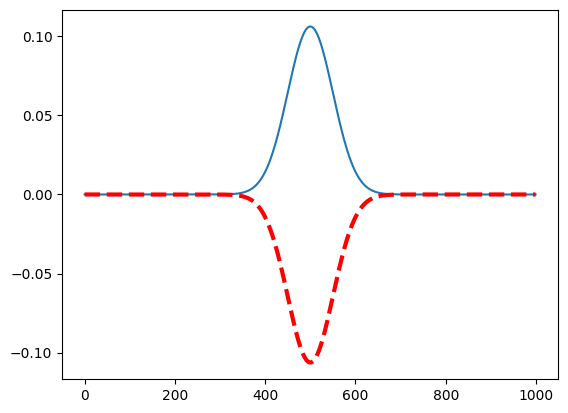

In [256]:
c, b = A.SHO_wvfn(0)

plt.plot( (V[:,0]))
plt.plot( -b, linestyle='dashed',color='red', lw=3)

checkin Udag matrix

In [257]:
N = 300
NSM = 100 
NSC = 100            ### DOESNT' MATTER WHAT WE PTU N, NSSC, NSM AS ATLEAST FOR THIS NOTEBOOK  
M = 100 
AX = 1
AY = 1 
LY = (M//10)*AY

MEFF_SC = 0.023 
MEFF_SM = 0.023 

OMEGA =  2*4*hbm/LY**2/MEFF_SC

print(OMEGA/2)

print(OMEGA/2 + hbm/MEFF_SC*math.pi**2/(N+1)**2/AX**2)

print(4*hbm/MEFF_SC/AX**2)

KNUM= 8 

A = twoD_Minimal_Model(N,NSM,NSC,M,AX,AY,OMEGA,meff_sc=MEFF_SC, meff_sm=MEFF_SM)

H = A.SHO_Hamiltonian_in_y()

E, V = eigsh(H , k = KNUM, sigma=0 )

print(E)

print(V.shape)

66.31720133634798
66.4978076602785
6631.720133634798
[66.33159539 66.87338977 67.77631483 69.0402722  70.66512419 72.65069382
 74.99676478 77.7030815 ]
(30000, 8)


In [258]:

t1 = time.time()
ud = A.U_dag(10)
u = A.U_dag(10).conjugate().transpose()
t2 = time.time()

print(t2-t1)

0.6386110782623291


In [259]:
W = ud.dot(H).dot(u)

In [260]:
print(W.shape)

(3000, 3000)


In [261]:
print(W.diagonal())

[3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.01202641 3382.01202641 3382.01202641 3382.01202641 3382.01202641
 3382.

In [262]:
E, V = eigsh(H , k = KNUM, sigma=0 )

print(E)

print(V.shape)

[66.33159539 66.87338977 67.77631483 69.0402722  70.66512419 72.65069382
 74.99676478 77.7030815 ]
(30000, 8)


In [263]:
E2, V2 = eigsh(W , k = KNUM, sigma=0 )

print(E2)

print(V2.shape)

[66.33159539 66.87338977 67.77631483 69.0402722  70.66512419 72.65069382
 74.99676478 77.7030815 ]
(3000, 8)


In [264]:
N = 300
NSM = 100 
NSC = 100           
M = 100 
AX = 1
AY = 1 
LY = (M//10)*AY

MEFF_SC = 0.023
MEFF_SM = 0.023 

OMEGA =  2*4*hbm/LY**2/MEFF_SC

print(OMEGA/2)

print(OMEGA/2 + hbm*math.pi**2/(N+1)**2/AX**2)

print(4*hbm/AX**2)

KNUM= 8 

A = twoD_Minimal_Model(N,NSM,NSC,M,AX,AY,OMEGA, meff_sc=MEFF_SC, meff_sm=MEFF_SM)

H = A.SHO_Hamiltonian_in_y_ph()

E, V = eigsh(H , k = KNUM, sigma=0 )

print(E)

print(V.shape)

66.31720133634798
66.32135528179838
152.52956307360034
[-69.0402722  -67.77631483 -66.87338977 -66.33159539  66.33159539
  66.87338977  67.77631483  69.0402722 ]
(60000, 8)


In [265]:
t1 = time.time()
ud = A.U_dag_ph(10)
u = A.U_dag_ph(10).conjugate().transpose()
t2 = time.time()

print(t2-t1)

1.2421612739562988


In [266]:
H.shape

(60000, 60000)

In [267]:
u.shape

(60000, 6000)

In [268]:
W = ud.dot(H).dot(u)

In [269]:
print(W.shape)

(6000, 6000)


In [270]:
print(W.diagonal())

[ 3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01202641  3382.01202641  3382.01202641
  3382.01202641  3382.01

In [271]:
E3, V3 = eigsh(W , k = KNUM, sigma=0 )

print(E3)

print(V3.shape)

[-69.0402722  -67.77631483 -66.87338977 -66.33159539  66.33159539
  66.87338977  67.77631483  69.0402722 ]
(6000, 8)
